# 04 — Validación de supuestos

**Proyecto:** Análisis de Elasticidad de Demanda en Delivery de Comida (v2)
**Fase:** 4 — Validación de supuestos

Se valida el modelo seleccionado en la Fase 3 (log-log con controles, elasticidad = -0.7513).

Objetivos de este notebook:
1. Test de Breusch-Pagan para heterocedasticidad
2. Cálculo de VIF para multicolinealidad entre variables numéricas
3. Evaluación de normalidad de residuos (Jarque-Bera + Q-Q plot)
4. Discusión de limitaciones de identificación causal


In [1]:
import sys
sys.path.append('../src')

import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

from modeling import modelo_log_log_controles
from diagnostics import test_breusch_pagan, calcular_vif, resumen_normalidad_residuos

pd.set_option('display.max_columns', None)

In [2]:
from pathlib import Path

REPORTS_DIR = Path('../reports')
NOTEBOOK_OUTPUTS_DIR = REPORTS_DIR / 'notebook_outputs'
FIGURES_DIR = REPORTS_DIR / 'figuras'
NOTEBOOK_OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def guardar_texto(nombre_archivo: str, contenido: str) -> Path:
    ruta = NOTEBOOK_OUTPUTS_DIR / nombre_archivo
    ruta.write_text(str(contenido), encoding='utf-8')
    return ruta


def guardar_tabla(nombre_base: str, tabla: pd.DataFrame) -> tuple[Path, Path]:
    ruta_txt = NOTEBOOK_OUTPUTS_DIR / f'{nombre_base}.txt'
    ruta_csv = NOTEBOOK_OUTPUTS_DIR / f'{nombre_base}.csv'
    tabla.to_csv(ruta_csv, index=False)
    ruta_txt.write_text(tabla.to_string(index=False), encoding='utf-8')
    return ruta_txt, ruta_csv

## 1. Cargar datos y reajustar el modelo seleccionado

In [3]:
df = pd.read_csv('../data/processed/demanda_limpia.csv')
modelo = modelo_log_log_controles(df)
texto_modelo = f'Modelo reajustado. Elasticidad: {modelo.params["log_checkout_price"]}'
ruta_modelo = guardar_texto('04_validacion_supuestos_modelo_reajustado.txt', texto_modelo)
print(texto_modelo)
print(f'Guardado en {ruta_modelo}')

Modelo reajustado. Elasticidad: -0.751263854618024
Guardado en ..\reports\notebook_outputs\04_validacion_supuestos_modelo_reajustado.txt


## 2. Test de Breusch-Pagan (heterocedasticidad)

**Qué hace:** el test de Breusch-Pagan evalúa si la varianza de los residuos
del modelo depende de los valores de las variables independientes. Se ajusta
una regresión auxiliar de los residuos al cuadrado sobre las variables
explicativas del modelo original, y se prueba si esa regresión auxiliar
tiene poder explicativo significativo.

**Hipótesis:**
- H0: homocedasticidad (varianza constante de los errores)
- H1: heterocedasticidad (la varianza cambia sistemáticamente)

**Por qué importa:** si hay heterocedasticidad, los coeficientes del modelo
siguen siendo insesgados, pero los errores estándar clásicos (los que
aparecen en el `summary()` de la Fase 3) dejan de ser confiables, lo que
afecta la validez de los intervalos de confianza y las pruebas de
significancia.

In [4]:
resultado_bp = test_breusch_pagan(modelo)
ruta_bp_txt, ruta_bp_csv = guardar_tabla('04_validacion_supuestos_breusch_pagan', resultado_bp)
print(f'Resultados guardados en {ruta_bp_csv} y {ruta_bp_txt}')
resultado_bp

Resultados guardados en ..\reports\notebook_outputs\04_validacion_supuestos_breusch_pagan.csv y ..\reports\notebook_outputs\04_validacion_supuestos_breusch_pagan.txt


,estadistico,valor,p_valor
0,LM,34632.474334,0.0
1,F,1972.294812,0.0


**Interpretación esperada:** con ~450,000 observaciones, es muy probable
que el test rechace homocedasticidad (p-valor prácticamente 0) incluso ante
heterocedasticidad de magnitud modesta — el test es muy sensible con
muestras grandes. Si esto ocurre, la acción estándar no es descartar el
modelo, sino reportar los coeficientes con **errores estándar robustos**
(HC3), que siguen siendo válidos bajo heterocedasticidad.

### 2.1 Reajuste con errores estándar robustos (si Breusch-Pagan confirma heterocedasticidad)

In [5]:
modelo_robusto = modelo.get_robustcov_results(cov_type='HC3')
ruta_robusto = guardar_texto('04_validacion_supuestos_modelo_robusto_summary.txt', modelo_robusto.summary().as_text())
print(modelo_robusto.summary())
print(f'Summary guardado en {ruta_robusto}')

                            OLS Regression Results                            
Dep. Variable:         log_num_orders   R-squared:                       0.531
Model:                            OLS   Adj. R-squared:                  0.531
Method:                 Least Squares   F-statistic:                 3.921e+04
Date:                Fri, 07 Aug 2026   Prob (F-statistic):               0.00
Time:                        17:22:05   Log-Likelihood:            -5.5924e+05
No. Observations:              456548   AIC:                         1.119e+06
Df Residuals:                  456528   BIC:                         1.119e+06
Df Model:                          19                                         
Covariance Type:                  HC3                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept         

**Comparar:** el coeficiente de `log_checkout_price` debe ser idéntico al
del modelo original (los errores robustos no cambian los coeficientes, solo
los errores estándar). Documentar si el error estándar cambió mucho respecto
al modelo original — si el cambio es pequeño, la heterocedasticidad no
afecta materialmente las conclusiones.

## 3. VIF — Factor de Inflación de Varianza (multicolinealidad)

**Qué hace:** para cada variable numérica, VIF mide cuánto se infla la
varianza de su coeficiente estimado debido a su correlación con las demás
variables independientes del modelo. Se calcula ajustando una regresión de
esa variable contra todas las demás y usando su R² resultante:
`VIF = 1 / (1 - R²)`.

**Por qué se calcula ahora:** este es el diagnóstico que responde a la
advertencia de "condition number alto" detectada en el modelo semi-log
durante la Fase 3 (ver bitácora, sección 3.3).

In [6]:
columnas_numericas = ['log_checkout_price', 'emailer_for_promotion',
                       'homepage_featured', 'hubo_aumento']

tabla_vif = calcular_vif(df, columnas_numericas)
ruta_vif_txt, ruta_vif_csv = guardar_tabla('04_validacion_supuestos_vif', tabla_vif)
print(f'VIF guardado en {ruta_vif_csv} y {ruta_vif_txt}')
tabla_vif

VIF guardado en ..\reports\notebook_outputs\04_validacion_supuestos_vif.csv y ..\reports\notebook_outputs\04_validacion_supuestos_vif.txt


,variable,VIF
0,log_checkout_price,1.008837
1,emailer_for_promotion,1.203580
2,homepage_featured,1.187567
3,hubo_aumento,1.028820


**Interpretación:** valores de VIF cercanos a 1 indican ausencia de
multicolinealidad relevante entre estas variables. Si todos los VIF están
por debajo de 5, se confirma que la advertencia de condition number del
semi-log se debía a la diferencia de escala entre `checkout_price` (valores
en cientos) y las dummies (0/1), no a una multicolinealidad real — hipótesis
planteada en la bitácora de la Fase 3.

## 4. Normalidad de residuos

**Qué hace:** el test de Jarque-Bera evalúa si la asimetría y curtosis de
los residuos son consistentes con una distribución normal. Se complementa
con un gráfico Q-Q, que compara visualmente los cuantiles de los residuos
contra los cuantiles teóricos de una normal — es más informativo que el
test formal para juzgar la magnitud real de la desviación, especialmente en
muestras grandes donde el test estadístico es demasiado sensible.

In [7]:
resumen_jb = resumen_normalidad_residuos(modelo)
ruta_jb = guardar_texto('04_validacion_supuestos_normalidad_residuos.txt', json.dumps(resumen_jb, ensure_ascii=False, indent=2))
print(resumen_jb)
print(f'Resumen guardado en {ruta_jb}')

{'jarque_bera_estadistico': np.float64(9002.068499287769), 'jarque_bera_pvalor': np.float64(0.0), 'asimetria': np.float64(-0.3306845820367336), 'curtosis': np.float64(3.1892490640640334)}
Resumen guardado en ..\reports\notebook_outputs\04_validacion_supuestos_normalidad_residuos.txt


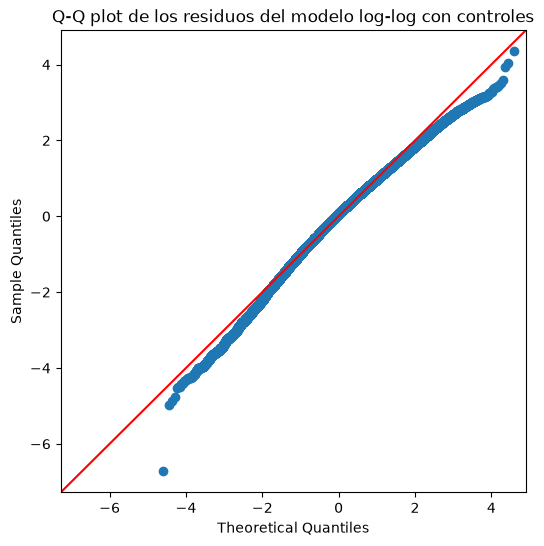

Q-Q plot guardado en ..\reports\figuras\qqplot_residuos_modelo_loglog_controles.png


In [8]:
fig = sm.qqplot(modelo.resid, line='45', fit=True)
fig.set_size_inches(6, 6)
plt.title('Q-Q plot de los residuos del modelo log-log con controles')
ruta_qq = FIGURES_DIR / 'qqplot_residuos_modelo_loglog_controles.png'
plt.savefig(ruta_qq, dpi=150, bbox_inches='tight')
plt.show()
print(f'Q-Q plot guardado en {ruta_qq}')

**Interpretación esperada:** es normal que los extremos de la distribución
(colas) se desvíen algo de la línea de 45°, incluso en modelos bien
especificados — lo relevante es si el grueso central de los puntos sigue de
cerca la línea. Documentar en la bitácora si se observan desviaciones
severas o solo en las colas.

## 5. Limitaciones de identificación causal

Este modelo es observacional, no experimental. Antes de interpretar el
coeficiente de precio como un efecto causal puro, se documentan las
siguientes limitaciones:

- **Precios no asignados aleatoriamente:** el precio de cada comida/semana
  probablemente responde, al menos en parte, a decisiones de la empresa
  basadas en demanda esperada — lo que introduce posible simultaneidad
  (causalidad en ambas direcciones entre precio y demanda)
- **Variables omitidas potenciales:** factores como campañas de marketing no
  capturadas en el dataset, estacionalidad fuerte (feriados, clima), o
  eventos puntuales por centro, podrían correlacionar tanto con el precio
  como con la demanda, sesgando el coeficiente estimado
- **Efectos fijos por semana no incluidos:** el modelo controla por
  categoría y tipo de centro, pero no por semana — tendencias temporales
  generales (crecimiento de la plataforma, estacionalidad) quedan sin
  controlar explícitamente

**Conclusión metodológica:** el coeficiente de -0.75 se reporta e interpreta
como una **asociación robusta**, consistente entre especificaciones y
validada estadísticamente, más que como un efecto causal identificado con
el rigor de un diseño experimental o cuasi-experimental (que requeriría,
por ejemplo, variación de precio exógena o un instrumento válido).

## Próximos pasos (Fase 5 — comparación con literatura)
- Extraer elasticidades reportadas de 6-10 papers sobre demanda de delivery
- Armar tabla comparativa con la elasticidad propia (-0.7513) incluida
- Gráfico de puntos con barras de error
- Discusión de consistencia/divergencia con la literatura